# Learned collaborative filtering: BPR-MF and EASE

This notebook compares **BPR matrix factorization**, **EASE**, and the existing
item-based CF / plot-TF-IDF hybrid on the canonical per-user chronological
60/20/20 split. It is a new **validation experiment**: notebook 07 has already
reported test results, so those outcomes cannot serve as an untouched final
assessment for these new models.

Run notebook **01** to create the split and notebook **04** to create the
split-specific plot catalogs. Baselines are rebuilt here, so notebooks 02,
05, 06, and the final-test section of 07 are not prerequisites. If compatible
validation artifacts from 01, 02, or 07 exist, their user-level results are
checked against the rebuilt baselines.

**Evaluation contract:** likes are ratings >= 4.0; candidates are every movie
rated in training; exclude every movie the target user rated in training.
Evaluate all users with validation likes, including users with no training
likes. Keep unavailable held-out movies in the Recall@10 denominator. Rank
the full eligible catalog, with training rating count and then movie ID
breaking score ties. Mean metrics give each user equal weight.

Recall@10 selects settings. Binary NDCG@10 is an additional diagnostic; its
ideal ranking contains min(10, all held-out positives), including unavailable
movies. Neither metric uses sampled evaluation negatives.

Sources: [Rendle et al., BPR, UAI 2009](https://arxiv.org/abs/1205.2618) and
[Steck, EASE, WWW 2019](https://arxiv.org/abs/1905.03375).


## Load and verify training and validation

Use the same manifest and exact CSVs as the preceding notebooks. This
notebook never opens the held-out test CSV or final-test results. The output
folder belongs to notebook 08, so its exploratory choices do not replace
notebook 07's frozen selection.


In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.linalg import cho_factor, cho_solve
from scipy.special import expit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from threadpoolctl import threadpool_limits

SPLIT_ID = "per_user_chronological_60_20_20_v1"
POSITIVE_THRESHOLD = 4.0
TOP_K = 10
SEED = 42

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "raw" / "ml-latest-small").is_dir()), None
)
if project_root is None:
    raise FileNotFoundError("Run from inside the MovieLens project.")
raw_dir = project_root / "data" / "raw" / "ml-latest-small"
processed_dir = project_root / "data" / "processed" / SPLIT_ID
manifest_path = processed_dir / "split_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("Run notebook 01 first to create the canonical split.")
split_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert split_manifest["split_id"] == SPLIT_ID
assert split_manifest["positive_threshold"] == POSITIVE_THRESHOLD
assert split_manifest["top_k"] == TOP_K

def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

for filename, expected_hash in split_manifest["raw_sha256"].items():
    if file_sha256(raw_dir / filename) != expected_hash:
        raise ValueError(f"{filename} changed; regenerate the split in notebook 01.")

movies = pd.read_csv(raw_dir / "movies.csv")
loaded_splits = {}
for name in ("train", "validation"):
    path = processed_dir / f"{name}_ratings.csv"
    expected = split_manifest["files"][path.name]
    if file_sha256(path) != expected["sha256"]:
        raise ValueError(f"{path.name} differs from the canonical split.")
    loaded_splits[name] = pd.read_csv(path, parse_dates=["rated_at"])
    assert len(loaded_splits[name]) == expected["rows"]
train_ratings = loaded_splits["train"]
validation_ratings = loaded_splits["validation"]
assert not train_ratings.duplicated(["userId", "movieId"]).any()
assert not validation_ratings.duplicated(["userId", "movieId"]).any()
assert set(map(tuple, train_ratings[["userId", "movieId"]].to_numpy())).isdisjoint(
    map(tuple, validation_ratings[["userId", "movieId"]].to_numpy())
)
assert (train_ratings.groupby("userId")["timestamp"].max()
        <= validation_ratings.groupby("userId")["timestamp"].min()).all()

output_dir = processed_dir / "notebook08_learned_cf"
output_dir.mkdir(parents=True, exist_ok=True)

def with_provenance(frame):
    saved = frame.copy()
    for column, value in {
        "split_id": SPLIT_ID,
        "split_fingerprint": split_manifest["split_fingerprint"],
        "evaluation_split": "validation",
        "positive_threshold": POSITIVE_THRESHOLD,
        "k": TOP_K,
    }.items():
        saved[column] = value
    return saved

def check_provenance(frame, label):
    for column, value in {
        "split_id": SPLIT_ID,
        "split_fingerprint": split_manifest["split_fingerprint"],
        "evaluation_split": "validation",
        "positive_threshold": POSITIVE_THRESHOLD,
        "k": TOP_K,
    }.items():
        assert column in frame and frame[column].eq(value).all(), (
            f"{label}: incompatible {column}; rerun its source notebook."
        )

print("Python:", platform.python_version())
print("Split:", SPLIT_ID)
print("Training / validation ratings:", len(train_ratings), "/", len(validation_ratings))
print("Outputs:", output_dir)


Python: 3.14.8
Split: per_user_chronological_60_20_20_v1
Training / validation ratings: 60255 / 20164
Outputs: C:\Users\clark\OneDrive\Documents\Python Scripts\movie-recommendation-system\data\processed\per_user_chronological_60_20_20_v1\notebook08_learned_cf


## Build aligned feedback and candidate arrays

X contains one for each training like and zero otherwise. A zero is a
missing positive signal, not a verified dislike. Low-rated training movies
still belong to the catalog and to the seen-item exclusions.

Both new models use this same binary representation. BPR samples alternatives
from all training-catalog movies outside the user's training likes, including
low-rated movies and unrated movies. It never consults validation preferences
when constructing training triples. Users without training likes receive the
same popularity fallback for every model.


In [2]:
user_ids = np.sort(train_ratings["userId"].unique())
movie_ids = np.sort(train_ratings["movieId"].unique())
user_index = pd.Index(user_ids)
movie_index = pd.Index(movie_ids)
n_users, n_items = len(user_ids), len(movie_ids)

X = np.zeros((n_users, n_items), dtype=np.float64)
seen = np.zeros((n_users, n_items), dtype=bool)
train_u = user_index.get_indexer(train_ratings["userId"])
train_i = movie_index.get_indexer(train_ratings["movieId"])
seen[train_u, train_i] = True
positive_rows = train_ratings["rating"].ge(POSITIVE_THRESHOLD).to_numpy()
X[train_u[positive_rows], train_i[positive_rows]] = 1.0
liked_counts = X.sum(axis=1).astype(int)
popularity_counts = np.bincount(train_i, minlength=n_items)

validation_positives = validation_ratings.loc[
    validation_ratings["rating"].ge(POSITIVE_THRESHOLD)
]
positive_ids_by_user = {
    int(user_id): set(group["movieId"].astype(int))
    for user_id, group in validation_positives.groupby("userId", sort=True)
}
evaluation_user_ids = np.array(sorted(positive_ids_by_user), dtype=int)
if len(evaluation_user_ids) == 0:
    raise ValueError("No validation users have positive feedback.")
assert user_index.get_indexer(evaluation_user_ids).min() >= 0
assert X.sum() == positive_rows.sum()
assert seen.sum() == len(train_ratings)
assert popularity_counts.sum() == len(train_ratings)

# Keep chronological liked-item order to reproduce notebook 07's averaging.
liked_columns_by_user = [
    movie_index.get_indexer(
        train_ratings.loc[
            train_ratings["userId"].eq(user_id)
            & train_ratings["rating"].ge(POSITIVE_THRESHOLD), "movieId"
        ]
    )
    for user_id in user_ids
]
print("Binary feedback shape:", X.shape)
print("Training likes:", int(X.sum()))
print("Validation-positive users:", len(evaluation_user_ids))
print("Eligible users without training likes:",
      int((liked_counts[user_index.get_indexer(evaluation_user_ids)] == 0).sum()))


Binary feedback shape: (610, 6885)
Training likes: 29862
Validation-positive users: 594
Eligible users without training likes: 1


## Use one ranking and metric implementation

The ranking routine applies identical exclusions, fallback behavior, and tie
rules to all models. It retains ordered recommendation rows so NDCG and
example lists can be inspected. Signed EASE and BPR scores are preserved;
zero is not a score cutoff.


In [3]:
def rank_candidates(scores, candidate_movie_ids, rating_counts, seen_mask,
                    has_likes=True, k=10):
    """Return catalog column positions in deterministic recommendation order."""
    scores = np.asarray(scores, dtype=float)
    if scores.shape != candidate_movie_ids.shape or seen_mask.shape != scores.shape:
        raise ValueError("Scores and candidate arrays must have matching shapes.")
    if not np.isfinite(scores).all():
        raise ValueError("Candidate scores must all be finite.")
    if k < 1:
        raise ValueError("k must be positive.")
    positions = np.flatnonzero(~seen_mask)
    ranking_scores = scores if has_likes else np.zeros_like(scores)
    order = np.lexsort((
        candidate_movie_ids[positions],
        -rating_counts[positions],
        -ranking_scores[positions],
    ))
    return positions[order[:k]]

def ranking_metrics(recommended_ids, positive_ids, k=10):
    """Binary Recall/NDCG with every held-out positive in the denominator."""
    if not positive_ids:
        raise ValueError("Recall requires at least one held-out positive.")
    recommended_ids = list(recommended_ids)[:k]
    if len(set(recommended_ids)) != len(recommended_ids):
        raise ValueError("Recommendations must be unique.")
    relevance = np.array([movie_id in positive_ids for movie_id in recommended_ids])
    discounts = 1.0 / np.log2(np.arange(2, len(recommended_ids) + 2))
    hits = int(relevance.sum())
    dcg = float(np.sum(relevance * discounts))
    idcg = float(np.sum(1.0 / np.log2(np.arange(2, min(k, len(positive_ids)) + 2))))
    return hits, hits / len(positive_ids), dcg / idcg

def evaluate_scores(scores):
    """Evaluate aligned user-by-catalog scores against validation only."""
    if scores.shape != X.shape or not np.isfinite(scores).all():
        raise ValueError("Expected finite scores aligned with training X.")
    rows, recommendations = [], []
    candidate_set = set(movie_ids)
    for user_id in evaluation_user_ids:
        u = user_index.get_loc(user_id)
        columns = rank_candidates(
            scores[u], movie_ids, popularity_counts, seen[u],
            has_likes=bool(liked_counts[u]), k=TOP_K,
        )
        rec_ids = movie_ids[columns]
        positives = positive_ids_by_user[int(user_id)]
        assert len(rec_ids) == min(TOP_K, int((~seen[u]).sum()))
        assert len(np.unique(rec_ids)) == len(rec_ids)
        assert not seen[u, columns].any()
        hits, recall, ndcg = ranking_metrics(rec_ids, positives, TOP_K)
        rows.append({
            "userId": int(user_id),
            "positive_movie_count": len(positives),
            "positive_movies_in_training_catalog": len(positives & candidate_set),
            "recommended_movie_count": len(rec_ids),
            "hits_at_10": hits, "recall_at_10": recall, "ndcg_at_10": ndcg,
            "has_training_history": True,
            "has_liked_training_history": bool(liked_counts[u]),
            "training_rating_count": int(seen[u].sum()),
            "training_like_count": int(liked_counts[u]),
        })
        for rank, (column, movie_id) in enumerate(zip(columns, rec_ids), start=1):
            recommendations.append({
                "userId": int(user_id), "rank": rank, "movieId": int(movie_id),
                "score": float(scores[u, column]) if liked_counts[u] else 0.0,
                "is_validation_positive": movie_id in positives,
            })
    result = pd.DataFrame(rows)
    assert result["userId"].is_unique
    assert result["recall_at_10"].between(0, 1).all()
    assert result["ndcg_at_10"].between(0, 1 + 1e-12).all()
    return result, pd.DataFrame(recommendations)

def summarize(results):
    return {
        "users": len(results),
        "mean_recall_at_10": float(results["recall_at_10"].mean()),
        "mean_ndcg_at_10": float(results["ndcg_at_10"].mean()),
        "total_hits_at_10": int(results["hits_at_10"].sum()),
    }


## Rebuild popularity, item-based CF, and the original hybrid

Only the plot catalogs from notebook 04 are needed. Their hashes and split
provenance must match. The CF cosine calculations, plot representation,
unseen-candidate max scaling, and hybrid weight grid reproduce notebook 07.
Missing plots leave movies in the candidate catalog with zero text evidence.

The hybrid selects its plot weight by mean validation Recall@10, with lower
weight breaking an exact tie. Rebuilding these lists makes NDCG comparable
across every model, rather than trying to infer it from saved hit counts.


In [4]:
plot_manifest_path = processed_dir / "plot_catalog_manifest.json"
if not plot_manifest_path.is_file():
    raise FileNotFoundError("Run notebook 04 first to create the plot catalogs.")
plot_manifest = json.loads(plot_manifest_path.read_text(encoding="utf-8"))
assert plot_manifest["split_id"] == SPLIT_ID
assert plot_manifest["split_fingerprint"] == split_manifest["split_fingerprint"]
for filename in ("movie_plot_catalog.csv", "training_plot_catalog.csv"):
    assert file_sha256(processed_dir / filename) == plot_manifest["files"][filename]["sha256"]
plot_hash = file_sha256(processed_dir / "training_plot_catalog.csv")
plot_catalog = pd.read_csv(processed_dir / "training_plot_catalog.csv")
assert plot_catalog["movieId"].is_unique
assert set(plot_catalog["movieId"]) == set(movie_ids)
text_movies = (
    plot_catalog.loc[plot_catalog["plot"].fillna("").str.strip().ne("")]
    .sort_values("movieId").reset_index(drop=True)
)
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", min_df=2, norm="l2")
plot_tfidf = tfidf.fit_transform(text_movies["plot"])
text_columns = movie_index.get_indexer(text_movies["movieId"])

baseline_started = perf_counter()
cf_scores = np.zeros_like(X)
text_scores = np.zeros_like(X)
with threadpool_limits(limits=2, user_api="blas"):
    for u in user_index.get_indexer(evaluation_user_ids):
        liked_columns = liked_columns_by_user[u]
        if len(liked_columns):
            cf_scores[u] = cosine_similarity(X[:, liked_columns].T, X.T).mean(axis=0)
            text_rows = np.flatnonzero(
                text_movies["movieId"].isin(movie_ids[liked_columns]).to_numpy()
            )
            if len(text_rows):
                text_scores[u, text_columns] = cosine_similarity(
                    plot_tfidf[text_rows], plot_tfidf
                ).mean(axis=0)

def hybrid_scores_for_weight(cf, text, seen_mask, weight):
    if not 0 <= weight <= 1:
        raise ValueError("Plot weight must be between zero and one.")
    blended = cf.copy()
    if weight == 0:
        return blended
    for u in range(len(cf)):
        eligible = ~seen_mask[u]
        if not eligible.any():
            continue
        text_max = text[u, eligible].max()
        if text_max <= 0:
            continue
        cf_max = cf[u, eligible].max()
        cf_part = (1 - weight) * cf[u] / cf_max if cf_max > 0 else 0.0
        blended[u] = cf_part + weight * text[u] / text_max
    return blended

baseline_results = {}
baseline_recommendations = {}
for label, scores in [
    ("Popularity", np.zeros_like(X)),
    ("Item-based CF", cf_scores),
]:
    baseline_results[label], baseline_recommendations[label] = evaluate_scores(scores)

HYBRID_WEIGHTS = [0.0, 0.10, 0.25, 0.50]
hybrid_trials = []
hybrid_evaluations = {}
for weight in HYBRID_WEIGHTS:
    result, recs = evaluate_scores(hybrid_scores_for_weight(cf_scores, text_scores, seen, weight))
    hybrid_trials.append({"plot_weight": weight, **summarize(result)})
    hybrid_evaluations[weight] = (result, recs)
hybrid_grid = pd.DataFrame(hybrid_trials).sort_values(
    ["mean_recall_at_10", "plot_weight"], ascending=[False, True]
).reset_index(drop=True)
best_hybrid_weight = float(hybrid_grid.iloc[0]["plot_weight"])
baseline_results["Hybrid"], baseline_recommendations["Hybrid"] = hybrid_evaluations[best_hybrid_weight]
assert baseline_results["Item-based CF"].equals(hybrid_evaluations[0.0][0])

# Check saved canonical results when available; never read unscoped old CSVs.
def check_saved_baseline(current, saved, label):
    check_provenance(saved, label)
    assert saved["userId"].is_unique, label
    paired = current.merge(
        saved[["userId", "positive_movie_count", "hits_at_10", "recall_at_10"]],
        on="userId", how="outer", suffixes=("_new", "_saved"),
        indicator=True, validate="one_to_one",
    )
    assert paired["_merge"].eq("both").all(), label
    for column in ("positive_movie_count", "hits_at_10"):
        assert paired[f"{column}_new"].eq(paired[f"{column}_saved"]).all(), label
    assert np.allclose(paired["recall_at_10_new"], paired["recall_at_10_saved"]), label

for label, filename in [
    ("Popularity", "popularity_validation_results.csv"),
    ("Item-based CF", "item_based_validation_results.csv"),
]:
    path = processed_dir / filename
    if path.is_file():
        check_saved_baseline(baseline_results[label], pd.read_csv(path), label)
hybrid_path = processed_dir / "hybrid_validation_results.csv"
if hybrid_path.is_file():
    saved_hybrid = pd.read_csv(hybrid_path)
    check_provenance(saved_hybrid, "Hybrid")
    assert saved_hybrid["plot_catalog_sha256"].eq(plot_hash).all()
    assert set(saved_hybrid["plot_weight"]) == set(HYBRID_WEIGHTS)
    for weight, (result, _) in hybrid_evaluations.items():
        check_saved_baseline(
            result, saved_hybrid.loc[saved_hybrid["plot_weight"].eq(weight)], "Hybrid"
        )

print(f"Baselines rebuilt and checked in {perf_counter() - baseline_started:.1f} seconds.")
print("Selected hybrid plot weight:", best_hybrid_weight)
display(hybrid_grid)
del cf_scores, text_scores, hybrid_evaluations


Baselines rebuilt and checked in 33.3 seconds.
Selected hybrid plot weight: 0.25


,plot_weight,users,mean_recall_at_10,mean_ndcg_at_10,total_hits_at_10
0,0.25,594,0.117784,0.140445,619
1,0.10,594,0.115148,0.139741,608
2,0.00,594,0.112240,0.137102,590
3,0.50,594,0.083479,0.093662,432


## Declare the search before fitting the new models

Both families select by macro mean validation Recall@10 only. Exact ties
prefer the earlier declared trial: fewer BPR factors, stronger BPR
regularization, and earlier checkpoints; larger EASE regularization. NDCG
does not change selection. This is a modest search, not an exhaustive claim
about the best possible implementation of either family.

BPR uses four training trajectories with three checkpoints each. An epoch
visits every training-positive pair once in shuffled order and samples one
alternative per pair. Adam optimizes minibatch mean BPR loss, with penalties
on the sampled user and item embeddings. The seed and sampling scheme are
fixed. Checkpoint selection is validation tuning; no test refit follows.


In [5]:
BPR_GRID = [
    {"factors": factors, "regularization": regularization}
    for factors in (32, 64)
    for regularization in (0.01, 0.001)
]
BPR_CHECKPOINTS = [25, 75, 150]
BPR_LEARNING_RATE = 0.01
BPR_BATCH_SIZE = 1024
EASE_L2_GRID = [1000.0, 300.0, 100.0, 50.0, 10.0, 1.0]
experiment_plan = {
    "stage": "exploratory validation after notebook07",
    "selection_metric": "macro mean Recall@10",
    "secondary_metric": "binary NDCG@10; all held-out positives define ideal DCG",
    "tie_rule": "earlier declared trial",
    "seed": SEED,
    "bpr_grid": BPR_GRID, "bpr_checkpoints": BPR_CHECKPOINTS,
    "bpr_learning_rate": BPR_LEARNING_RATE, "bpr_batch_size": BPR_BATCH_SIZE,
    "bpr_optimizer": "dense Adam, beta1=0.9, beta2=0.999, epsilon=1e-8",
    "bpr_sampling": "one shuffled pass of training positives per epoch; uniform non-like alternatives",
    "ease_l2_grid": EASE_L2_GRID,
    "hybrid_weights": HYBRID_WEIGHTS,
    "candidate_policy": split_manifest["candidate_policy"],
    "recall_denominator": split_manifest["recall_denominator"],
    "positive_threshold": POSITIVE_THRESHOLD, "k": TOP_K,
    "split_id": SPLIT_ID,
    "split_fingerprint": split_manifest["split_fingerprint"],
    "plot_catalog_sha256": plot_hash,
}
(output_dir / "experiment_plan.json").write_text(
    json.dumps(experiment_plan, indent=2, sort_keys=True) + "\n", encoding="utf-8"
)
display(pd.DataFrame(BPR_GRID))
print("BPR checkpoints:", BPR_CHECKPOINTS)
print("EASE regularization:", EASE_L2_GRID)


BPR checkpoints: [25, 75, 150]
EASE regularization: [1000.0, 300.0, 100.0, 50.0, 10.0, 1.0]


,factors,regularization
0,32,0.010
1,32,0.001
2,64,0.010
3,64,0.001


## BPR matrix factorization

Each user and movie has a learned vector. The score is their dot product:
$s(u,i)=p_u^\top q_i$. For a training like $i$ and sampled alternative $j$,
minimize
$\log(1+\exp[-p_u^\top(q_i-q_j)])+
\frac{\lambda}{2}(\|p_u\|^2+\|q_i\|^2+\|q_j\|^2)$.

The implementation uses NumPy and SciPy already in the project. Repeated
users or movies within a minibatch accumulate their gradients with
np.add.at. Initialization and training sampling use separate seeded random
generators so changing the factor dimension does not change sampled pairs.
A fixed training-only diagnostic sample tracks the objective, not validation
performance. Scores are ranking utilities, not predicted stars.


In [6]:
def sample_bpr_negatives(feedback, users, rng, positive_counts=None):
    """Uniformly sample outside each user's positive training set."""
    if positive_counts is None:
        positive_counts = np.count_nonzero(feedback, axis=1)
    if np.any(positive_counts[users] == feedback.shape[1]):
        raise ValueError("A sampled user has no non-positive catalog alternatives.")
    negatives = rng.integers(feedback.shape[1], size=len(users))
    invalid = feedback[users, negatives] > 0
    while invalid.any():
        negatives[invalid] = rng.integers(feedback.shape[1], size=int(invalid.sum()))
        invalid = feedback[users, negatives] > 0
    return negatives

def bpr_loss_gradients(user_factors, item_factors, users, positives, negatives,
                       regularization):
    """Mean pairwise logistic objective and accumulated embedding gradients."""
    if len(users) == 0:
        raise ValueError("A BPR minibatch cannot be empty.")
    u = user_factors[users]
    positive = item_factors[positives]
    negative = item_factors[negatives]
    margin = np.sum(u * (positive - negative), axis=1)
    multiplier = expit(-margin)[:, None]
    penalty = regularization / 2 * (
        np.sum(u * u, axis=1)
        + np.sum(positive * positive, axis=1)
        + np.sum(negative * negative, axis=1)
    )
    loss = float(np.mean(np.logaddexp(0.0, -margin) + penalty))
    scale = 1.0 / len(users)
    grad_users = np.zeros_like(user_factors)
    grad_items = np.zeros_like(item_factors)
    np.add.at(
        grad_users, users,
        scale * (-multiplier * (positive - negative) + regularization * u),
    )
    np.add.at(
        grad_items, positives, scale * (-multiplier * u + regularization * positive)
    )
    np.add.at(
        grad_items, negatives, scale * (multiplier * u + regularization * negative)
    )
    return loss, grad_users, grad_items

def bpr_training_epochs(feedback, factors, regularization, epochs,
                        learning_rate=0.01, batch_size=1024, seed=42):
    """Yield epoch, current factor arrays, and a training-only diagnostic loss."""
    if factors < 1 or epochs < 1 or batch_size < 1 or regularization < 0 or learning_rate <= 0:
        raise ValueError("Invalid BPR training parameters.")
    positive_users, positive_items = np.nonzero(feedback)
    if len(positive_users) == 0:
        raise ValueError("BPR needs at least one training like.")
    positive_counts = np.count_nonzero(feedback, axis=1)
    if np.any(positive_counts == feedback.shape[1]):
        raise ValueError("Every training user needs at least one catalog alternative.")
    init_rng = np.random.default_rng(seed)
    sample_rng = np.random.default_rng(seed + 1)
    diagnostic_rng = np.random.default_rng(seed + 2)
    user_factors = init_rng.normal(0.0, 0.05, (feedback.shape[0], factors))
    item_factors = init_rng.normal(0.0, 0.05, (feedback.shape[1], factors))
    # No-like users are evaluated through popularity, independent of random factors.
    user_factors[np.count_nonzero(feedback, axis=1) == 0] = 0.0
    parameters = [user_factors, item_factors]
    first_moments = [np.zeros_like(array) for array in parameters]
    second_moments = [np.zeros_like(array) for array in parameters]
    diagnostic_rows = diagnostic_rng.choice(
        len(positive_users), size=min(4096, len(positive_users)), replace=False
    )
    diagnostic_users = positive_users[diagnostic_rows]
    diagnostic_positives = positive_items[diagnostic_rows]
    diagnostic_negatives = sample_bpr_negatives(feedback, diagnostic_users, diagnostic_rng, positive_counts)
    step = 0
    for epoch in range(1, epochs + 1):
        order = sample_rng.permutation(len(positive_users))
        for start in range(0, len(order), batch_size):
            rows = order[start:start + batch_size]
            users, positives = positive_users[rows], positive_items[rows]
            negatives = sample_bpr_negatives(feedback, users, sample_rng, positive_counts)
            _, grad_users, grad_items = bpr_loss_gradients(
                user_factors, item_factors, users, positives, negatives, regularization
            )
            step += 1
            for parameter, gradient, first, second in zip(
                parameters, [grad_users, grad_items], first_moments, second_moments
            ):
                first *= 0.9
                first += 0.1 * gradient
                second *= 0.999
                second += 0.001 * gradient * gradient
                corrected_first = first / (1 - 0.9 ** step)
                corrected_second = second / (1 - 0.999 ** step)
                parameter -= learning_rate * corrected_first / (np.sqrt(corrected_second) + 1e-8)
        if not all(np.isfinite(parameter).all() for parameter in parameters):
            raise FloatingPointError("BPR factors diverged.")
        diagnostic_loss, _, _ = bpr_loss_gradients(
            user_factors, item_factors, diagnostic_users, diagnostic_positives,
            diagnostic_negatives, regularization,
        )
        # The arrays are live training state: copy them when retaining a checkpoint.
        yield epoch, user_factors, item_factors, diagnostic_loss


## Fit BPR and select its validation checkpoint

Each line below reports one declared checkpoint. Training continues along
the same trajectory between checkpoints. The retained factors are copied
when a new best validation mean is found, avoiding accidental mutation as
later epochs run.


In [7]:
bpr_trials, bpr_training_trace = [], []
best_bpr_score = -np.inf
best_bpr_state = None
with threadpool_limits(limits=2, user_api="blas"):
    for run_id, config in enumerate(BPR_GRID):
        started = perf_counter()
        for epoch, user_factors, item_factors, diagnostic_loss in bpr_training_epochs(
            X, **config, epochs=max(BPR_CHECKPOINTS),
            learning_rate=BPR_LEARNING_RATE, batch_size=BPR_BATCH_SIZE, seed=SEED,
        ):
            bpr_training_trace.append({
                "run_id": run_id, **config, "epoch": epoch,
                "training_diagnostic_loss": diagnostic_loss,
            })
            if epoch not in BPR_CHECKPOINTS:
                continue
            result, recs = evaluate_scores(user_factors @ item_factors.T)
            trial = {
                "trial_order": len(bpr_trials), "run_id": run_id, **config,
                "epoch": epoch, "training_diagnostic_loss": diagnostic_loss,
                "elapsed_seconds": perf_counter() - started, **summarize(result),
            }
            bpr_trials.append(trial)
            if trial["mean_recall_at_10"] > best_bpr_score:
                best_bpr_score = trial["mean_recall_at_10"]
                best_bpr_trial = trial.copy()
                best_bpr_state = (user_factors.copy(), item_factors.copy())
                best_bpr_results, best_bpr_recommendations = result, recs
            print(
                f"BPR factors={config['factors']}, reg={config['regularization']}, "
                f"epoch={epoch}: Recall@10={trial['mean_recall_at_10']:.4%}, "
                f"NDCG@10={trial['mean_ndcg_at_10']:.4f}"
            )
bpr_search = pd.DataFrame(bpr_trials)
training_trace = pd.DataFrame(bpr_training_trace)
display(bpr_search.sort_values(
    ["mean_recall_at_10", "trial_order"], ascending=[False, True]
))


BPR factors=32, reg=0.01, epoch=25: Recall@10=7.5570%, NDCG@10=0.0953
BPR factors=32, reg=0.01, epoch=75: Recall@10=9.1517%, NDCG@10=0.1060
BPR factors=32, reg=0.01, epoch=150: Recall@10=9.4011%, NDCG@10=0.1065
BPR factors=32, reg=0.001, epoch=25: Recall@10=7.4584%, NDCG@10=0.0936
BPR factors=32, reg=0.001, epoch=75: Recall@10=8.5087%, NDCG@10=0.0981
BPR factors=32, reg=0.001, epoch=150: Recall@10=7.9180%, NDCG@10=0.0940
BPR factors=64, reg=0.01, epoch=25: Recall@10=7.9879%, NDCG@10=0.1003
BPR factors=64, reg=0.01, epoch=75: Recall@10=9.4952%, NDCG@10=0.1089
BPR factors=64, reg=0.01, epoch=150: Recall@10=9.3033%, NDCG@10=0.1074
BPR factors=64, reg=0.001, epoch=25: Recall@10=9.0387%, NDCG@10=0.1046
BPR factors=64, reg=0.001, epoch=75: Recall@10=7.8747%, NDCG@10=0.0978
BPR factors=64, reg=0.001, epoch=150: Recall@10=7.9049%, NDCG@10=0.0936


,trial_order,run_id,factors,regularization,epoch,training_diagnostic_loss,elapsed_seconds,users,mean_recall_at_10,mean_ndcg_at_10,total_hits_at_10
7,7,2,64,0.010,75,0.121781,28.766102,594,0.094952,0.108872,516
2,2,0,32,0.010,150,0.119033,31.339859,594,0.094011,0.106462,513
8,8,2,64,0.010,150,0.121274,57.003255,594,0.093033,0.107388,503
1,1,0,32,0.010,75,0.120276,15.883378,594,0.091517,0.105980,490
9,9,3,64,0.001,25,0.032053,9.776688,594,0.090387,0.104576,474
4,4,1,32,0.001,75,0.029383,15.286314,594,0.085087,0.098067,453
6,6,2,64,0.010,25,0.124652,9.763306,594,0.079879,0.100347,459
5,5,1,32,0.001,150,0.027326,29.682925,594,0.079180,0.094043,416
11,11,3,64,0.001,150,0.024908,57.470443,594,0.079049,0.093610,416
10,10,3,64,0.001,75,0.026169,29.231830,594,0.078747,0.097829,446


## EASE: regularized linear collaborative filtering

EASE minimizes $\|X-XB\|_F^2+\lambda\|B\|_F^2$ with
$\operatorname{diag}(B)=0$. If
$P=(X^\top X+\lambda I)^{-1}$, its weights satisfy
$B_{ij}=-P_{ij}/P_{jj}$ for $i\ne j$.

An item-space inverse would be large for this catalog. The Woodbury identity
gives the exact same fitted-user scores from a user-space Cholesky solve:
$Z=(\lambda I+XX^\top)^{-1}X$,
$P_{jj}=(1-\sum_u X_{uj}Z_{uj})/\lambda$,
and $XB=X-Z/\operatorname{diag}(P)$.

This uses a 610-by-610 solve for this dataset, retaining the full candidate
catalog. The implementation preserves negative scores and does not build
the dense item-by-item weight matrix. It returns scores for fitting users;
scoring a genuinely new user would need a separate profile-scoring path.


In [8]:
def ease_training_user_scores(feedback, regularization):
    """Exact EASE predictions for fitting users, using the smaller dual solve."""
    if regularization <= 0:
        raise ValueError("EASE regularization must be positive.")
    feedback = np.asarray(feedback, dtype=np.float64)
    if feedback.ndim != 2 or not np.isfinite(feedback).all():
        raise ValueError("EASE expects a finite user-by-item matrix.")
    gram = feedback @ feedback.T
    gram[np.diag_indices_from(gram)] += regularization
    factor = cho_factor(gram, lower=True, check_finite=True)
    z = cho_solve(factor, feedback, check_finite=True)
    precision_diagonal = (1.0 - np.sum(feedback * z, axis=0)) / regularization
    if not np.isfinite(precision_diagonal).all() or (precision_diagonal <= 0).any():
        raise FloatingPointError("EASE precision diagonal must be finite and positive.")
    scores = feedback - z / precision_diagonal[None, :]
    if not np.isfinite(scores).all():
        raise FloatingPointError("EASE produced non-finite scores.")
    return scores


In [9]:
ease_trials = []
best_ease_score = -np.inf
with threadpool_limits(limits=2, user_api="blas"):
    for trial_order, regularization in enumerate(EASE_L2_GRID):
        started = perf_counter()
        scores = ease_training_user_scores(X, regularization)
        result, recs = evaluate_scores(scores)
        trial = {
            "trial_order": trial_order, "regularization": regularization,
            "elapsed_seconds": perf_counter() - started, **summarize(result),
        }
        ease_trials.append(trial)
        if trial["mean_recall_at_10"] > best_ease_score:
            best_ease_score = trial["mean_recall_at_10"]
            best_ease_trial = trial.copy()
            best_ease_results, best_ease_recommendations = result, recs
        print(
            f"EASE reg={regularization:g}: "
            f"Recall@10={trial['mean_recall_at_10']:.4%}, "
            f"NDCG@10={trial['mean_ndcg_at_10']:.4f}"
        )
ease_search = pd.DataFrame(ease_trials)
display(ease_search.sort_values(
    ["mean_recall_at_10", "trial_order"], ascending=[False, True]
))


EASE reg=1000: Recall@10=11.3016%, NDCG@10=0.1371
EASE reg=300: Recall@10=11.6907%, NDCG@10=0.1448
EASE reg=100: Recall@10=12.0853%, NDCG@10=0.1474
EASE reg=50: Recall@10=12.2476%, NDCG@10=0.1456
EASE reg=10: Recall@10=11.1401%, NDCG@10=0.1328
EASE reg=1: Recall@10=8.9160%, NDCG@10=0.1064


,trial_order,regularization,elapsed_seconds,users,mean_recall_at_10,mean_ndcg_at_10,total_hits_at_10
3,3,50.0,0.513574,594,0.122476,0.145589,646
2,2,100.0,0.575770,594,0.120853,0.147404,655
1,1,300.0,0.557745,594,0.116907,0.144763,641
0,0,1000.0,0.500523,594,0.113016,0.137069,605
4,4,10.0,0.502329,594,0.111401,0.132778,602
5,5,1.0,0.507332,594,0.089160,0.106448,480


## Compare selected settings on the same validation users

Each new family's row reports its best declared validation trial. The hybrid
also selected its weight on validation. These are useful development scores,
not independent estimates after tuning. The table reports both metrics but
orders models by Recall@10, then a declared lightweight-first family order
for exact ties.

Paired changes show how many users gain or lose retrieval relative to the
hybrid. They do not establish a statistically confirmed improvement after
model selection.


In [10]:
all_results = {
    **baseline_results, "BPR-MF": best_bpr_results, "EASE": best_ease_results,
}
all_recommendations = {
    **baseline_recommendations,
    "BPR-MF": best_bpr_recommendations, "EASE": best_ease_recommendations,
}
family_order = ["Popularity", "Item-based CF", "Hybrid", "EASE", "BPR-MF"]
reference_counts = (
    baseline_results["Hybrid"].set_index("userId")["positive_movie_count"].sort_index()
)
for label, result in all_results.items():
    current = result.set_index("userId").sort_index()
    assert current.index.equals(reference_counts.index), label
    assert current["positive_movie_count"].eq(reference_counts).all(), label

comparison = pd.DataFrame([
    {"model": label, **summarize(result)}
    for label, result in all_results.items()
])
comparison["tie_preference"] = comparison["model"].map(
    {label: i for i, label in enumerate(family_order)}
)
comparison = comparison.sort_values(
    ["mean_recall_at_10", "tie_preference"], ascending=[False, True]
).drop(columns="tie_preference").reset_index(drop=True)
display(comparison.assign(
    mean_recall_at_10=comparison["mean_recall_at_10"].map("{:.4%}".format),
    mean_ndcg_at_10=comparison["mean_ndcg_at_10"].map("{:.4f}".format),
))

paired_rows = []
for label in ("BPR-MF", "EASE"):
    paired = all_results[label].merge(
        baseline_results["Hybrid"][["userId", "recall_at_10", "ndcg_at_10"]],
        on="userId", suffixes=("_model", "_hybrid"),
        how="outer", validate="one_to_one", indicator=True,
    )
    assert paired["_merge"].eq("both").all()
    change = paired["recall_at_10_model"] - paired["recall_at_10_hybrid"]
    paired_rows.append({
        "model": label, "users": len(paired),
        "mean_recall_gain_percentage_points": float(100 * change.mean()),
        "mean_ndcg_gain": float(
            (paired["ndcg_at_10_model"] - paired["ndcg_at_10_hybrid"]).mean()
        ),
        "users_improved": int(change.gt(0).sum()),
        "users_worsened": int(change.lt(0).sum()),
        "users_unchanged": int(change.eq(0).sum()),
    })
paired_changes = pd.DataFrame(paired_rows)
display(paired_changes)
print("Leading validation model:", comparison.iloc[0]["model"])
print("BPR choice:", {key: best_bpr_trial[key] for key in ("factors", "regularization", "epoch")})
print("EASE choice: regularization =", best_ease_trial["regularization"])


Leading validation model: EASE
BPR choice: {'factors': 64, 'regularization': 0.01, 'epoch': 75}
EASE choice: regularization = 50.0


,model,users,mean_recall_at_10,mean_ndcg_at_10,total_hits_at_10
0,EASE,594,12.2476%,0.1456,646
1,Hybrid,594,11.7784%,0.1404,619
2,Item-based CF,594,11.2240%,0.1371,590
3,BPR-MF,594,9.4952%,0.1089,516
4,Popularity,594,7.2092%,0.0882,391


,model,users,mean_recall_gain_percentage_points,mean_ndcg_gain,users_improved,users_worsened,users_unchanged
0,BPR-MF,594,-2.283196,-0.031574,93,156,345
1,EASE,594,0.469121,0.005143,124,109,361


## Inspect training behavior, history groups, and one example

The BPR curves use a fixed training-only sample; falling loss demonstrates
optimization, not generalization. History groups use training likes only,
so their definitions do not depend on validation outcomes. The example user
is the first eligible ID, selected deterministically.


Example user: 1


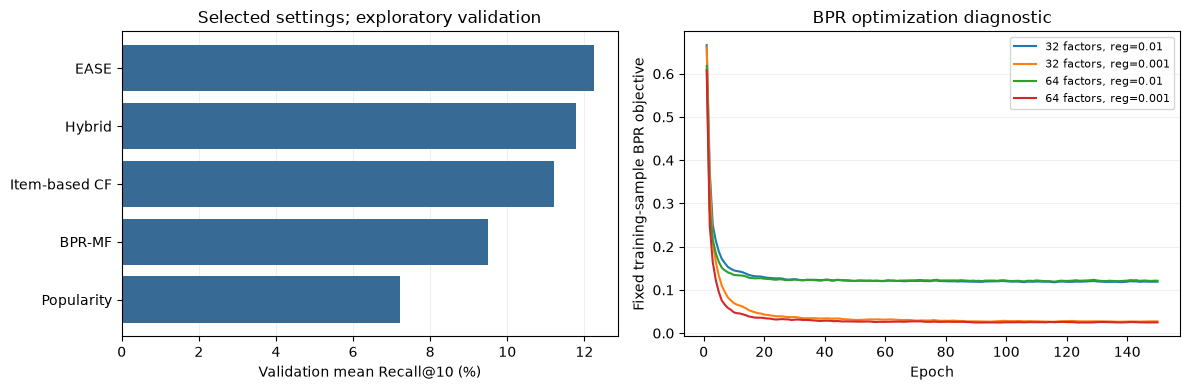

,model,training_like_group,users,mean_recall_at_10,mean_ndcg_at_10
0,BPR-MF,0,1,0.000000,0.000000
1,BPR-MF,1-10,118,0.129036,0.088327
2,BPR-MF,11-50,305,0.108930,0.095330
3,BPR-MF,51+,170,0.046776,0.148067
4,EASE,0,1,0.000000,0.000000
5,EASE,1-10,118,0.186265,0.143006
6,EASE,11-50,305,0.136682,0.125734
7,EASE,51+,170,0.053431,0.183859
8,Hybrid,0,1,0.000000,0.000000
9,Hybrid,1-10,118,0.177226,0.136093


,model,rank,title,is_validation_positive
0,Hybrid,1,"Terminator, The (1984)",False
1,Hybrid,2,Groundhog Day (1993),False
2,Hybrid,3,"Godfather, The (1972)",False
3,Hybrid,4,Goodfellas (1990),True
4,Hybrid,5,Terminator 2: Judgment Day (1991),False
5,Hybrid,6,"Fifth Element, The (1997)",False
6,Hybrid,7,"Hunt for Red October, The (1990)",False
7,Hybrid,8,Reservoir Dogs (1992),True
8,Hybrid,9,Ferris Bueller's Day Off (1986),False
9,Hybrid,10,Back to the Future (1985),False


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = comparison.iloc[::-1]
axes[0].barh(ordered["model"], 100 * ordered["mean_recall_at_10"], color="#376b96")
axes[0].set_xlabel("Validation mean Recall@10 (%)")
axes[0].set_title("Selected settings; exploratory validation")
for run_id, group in training_trace.groupby("run_id", sort=True):
    config = BPR_GRID[run_id]
    axes[1].plot(
        group["epoch"], group["training_diagnostic_loss"],
        label=f"{config['factors']} factors, reg={config['regularization']}",
    )
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Fixed training-sample BPR objective")
axes[1].set_title("BPR optimization diagnostic")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(axis="x" if ax is axes[0] else "y", alpha=0.2)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(output_dir / "validation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

per_user = pd.concat([
    result.assign(model=label) for label, result in all_results.items()
], ignore_index=True)
per_user["training_like_group"] = pd.cut(
    per_user["training_like_count"], bins=[-1, 0, 10, 50, np.inf],
    labels=["0", "1-10", "11-50", "51+"],
)
history_comparison = (
    per_user.groupby(["model", "training_like_group"], observed=True)
    .agg(users=("userId", "size"),
         mean_recall_at_10=("recall_at_10", "mean"),
         mean_ndcg_at_10=("ndcg_at_10", "mean"))
    .reset_index()
)
display(history_comparison)

example_user_id = int(evaluation_user_ids[0])
example = pd.concat([
    all_recommendations[label].loc[
        all_recommendations[label]["userId"].eq(example_user_id)
    ].assign(model=label)
    for label in ("Hybrid", "BPR-MF", "EASE")
], ignore_index=True).merge(
    movies[["movieId", "title"]], on="movieId", how="left", validate="many_to_one"
)
print("Example user:", example_user_id)
display(example[["model", "rank", "title", "is_validation_positive"]])


## Save this validation experiment separately

Save the complete search tables, selected per-user metrics, ordered
recommendations, and BPR factor checkpoint. The manifest records source,
split, plan, content, and output fingerprints plus package versions.
EASE can be reconstructed from its chosen regularization and canonical X.

All files remain under the ignored data directory. The selected settings
file is explicitly exploratory and does not replace notebook 07's frozen
selection, test predictions, or final report.


In [12]:
recommendations = pd.concat([
    recs.assign(model=label) for label, recs in all_recommendations.items()
], ignore_index=True)
artifacts = {
    "bpr_validation_trials.csv": bpr_search,
    "ease_validation_trials.csv": ease_search,
    "hybrid_validation_trials.csv": hybrid_grid,
    "bpr_training_trace.csv": training_trace,
    "validation_model_comparison.csv": comparison,
    "validation_per_user.csv": per_user,
    "validation_recommendations.csv": recommendations,
    "paired_changes_vs_hybrid.csv": paired_changes,
    "validation_by_history.csv": history_comparison,
}
for filename, frame in artifacts.items():
    with_provenance(frame).to_csv(output_dir / filename, index=False)

selected_settings = {
    "stage": "exploratory validation; no new test evaluation",
    "selection_metric": "macro mean Recall@10",
    "split_id": SPLIT_ID,
    "split_fingerprint": split_manifest["split_fingerprint"],
    "hybrid_plot_weight": best_hybrid_weight,
    "bpr": {key: best_bpr_trial[key] for key in (
        "factors", "regularization", "epoch", "mean_recall_at_10", "mean_ndcg_at_10"
    )},
    "ease": {key: best_ease_trial[key] for key in (
        "regularization", "mean_recall_at_10", "mean_ndcg_at_10"
    )},
    "leading_validation_model": str(comparison.iloc[0]["model"]),
}
settings_path = output_dir / "selected_validation_settings.json"
settings_path.write_text(
    json.dumps(selected_settings, indent=2, sort_keys=True) + "\n", encoding="utf-8"
)
np.savez_compressed(
    output_dir / "selected_bpr_factors.npz",
    user_factors=best_bpr_state[0], item_factors=best_bpr_state[1],
    user_ids=user_ids, movie_ids=movie_ids,
    split_fingerprint=split_manifest["split_fingerprint"],
    factors=best_bpr_trial["factors"],
    regularization=best_bpr_trial["regularization"],
    epoch=best_bpr_trial["epoch"],
)

notebook_path = project_root / "notebooks" / "08_learned_collaborative_filtering.ipynb"
notebook_sources = [
    {"cell_type": cell["cell_type"], "source": "".join(cell["source"])}
    for cell in json.loads(notebook_path.read_text(encoding="utf-8"))["cells"]
]
source_hash = hashlib.sha256(
    json.dumps(notebook_sources, sort_keys=True).encode("utf-8")
).hexdigest()
output_names = [
    *artifacts, "experiment_plan.json", "selected_validation_settings.json",
    "selected_bpr_factors.npz", "validation_comparison.png",
]
run_manifest = {
    **selected_settings,
    "notebook_source_sha256": source_hash,
    "plot_catalog_sha256": plot_hash,
    "raw_sha256": split_manifest["raw_sha256"],
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
    },
    "files": {
        filename: {"sha256": file_sha256(output_dir / filename)}
        for filename in output_names
    },
}
(output_dir / "run_manifest.json").write_text(
    json.dumps(run_manifest, indent=2, sort_keys=True) + "\n", encoding="utf-8"
)
print("Saved validation artifacts:", output_dir)
print("No test labels or previous final-test results were loaded.")


Saved validation artifacts: C:\Users\clark\OneDrive\Documents\Python Scripts\movie-recommendation-system\data\processed\per_user_chronological_60_20_20_v1\notebook08_learned_cf
No test labels or previous final-test results were loaded.


## What this experiment can establish

Read the recomputed table before deciding which model to develop further.
A learned model is useful here if it improves retrieval over the existing
hybrid on the same users and candidates. A lower BPR training loss alone is
not evidence of better recommendations. A weak result could reflect the
limited grid, training recipe, small dataset, or a mismatch between the
model's objective and this task.

Binary feedback discards differences among star ratings. Sampled BPR
alternatives can contain movies a user would actually like. These models
cannot personalize users without positive training history or recommend
movies outside the training catalog. The EASE shortcut scores existing
fitting users only. Training history is enforced within each user, rather
than across one global calendar boundary; plot snapshots are retrospective.

The validation set has now supported multiple rounds of development.
Selecting settings and reporting their scores on that same validation set
introduces selection optimism. Do not interpret these numbers or the
paired-change table as an untouched final test or an online user study.
Further development should keep the original test outcomes out of tuning
and use a declared fresh evaluation phase for an eventual final claim.
